In [1]:
import pandas as pd
import numpy as np
import os

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import LinearSVC

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import matplotlib.pyplot as plt

In [2]:
DATA_DIR = r"F:\EDAIC-WOZ\data"
LABEL_DIR = r"F:\EDAIC-WOZ\labels"

print("Data directory:", DATA_DIR)
print("Label directory:", LABEL_DIR)

print("Data folder exists:", os.path.exists(DATA_DIR))
print("Label folder exists:", os.path.exists(LABEL_DIR))

Data directory: F:\EDAIC-WOZ\data
Label directory: F:\EDAIC-WOZ\labels
Data folder exists: True
Label folder exists: True


In [5]:
train_labels = pd.read_csv(
    os.path.join(LABEL_DIR, "train_split.csv")
)

print("Train shape:", train_labels.shape)

print("\nColumns:")
print(train_labels.columns.tolist())

print("\nFirst 5 rows:")
display(train_labels.head())

Train shape: (163, 6)

Columns:
['Participant_ID', 'Gender', 'PHQ_Binary', 'PHQ_Score', 'PCL-C (PTSD)', 'PTSD Severity']

First 5 rows:


,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity
0,302,male,0,4,0,28
1,303,female,0,0,0,17
2,304,female,0,6,0,20
3,305,male,0,7,0,28
4,307,female,0,4,0,23


In [7]:
print("PHQ_Binary class distribution:")
print(
    train_labels["PHQ_Binary"]
    .value_counts()
    .sort_index()
)

print("\nClass percentages:")
print(
    train_labels["PHQ_Binary"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

PHQ_Binary class distribution:
PHQ_Binary
0    126
1     37
Name: count, dtype: int64

Class percentages:
PHQ_Binary
0    77.3
1    22.7
Name: proportion, dtype: float64


In [9]:
def extract_egemaps(pid):
    pid = int(pid)

    feature_path = os.path.join(
        DATA_DIR,
        f"{pid:03d}_P",
        "features",
        f"{pid:03d}_BoAW_openSMILE_2.3.0_eGeMAPS.csv"
    )

    df = pd.read_csv(
        feature_path,
        header=None
    )

    # Remove first 2 metadata columns
    features = df.iloc[:, 2:]

    # Statistical representations
    mean_features = features.mean(axis=0)
    std_features = features.std(axis=0)
    min_features = features.min(axis=0)
    max_features = features.max(axis=0)

    # Combine dynamically
    participant_features = np.concatenate([
        mean_features.values,
        std_features.values,
        min_features.values,
        max_features.values
    ])

    return participant_features

In [11]:
X_list = []
y_list = []
participant_ids = []

for _, row in train_labels.iterrows():

    pid = row["Participant_ID"]

    try:
        features = extract_egemaps(pid)

        X_list.append(features)
        y_list.append(row["PHQ_Binary"])
        participant_ids.append(pid)

    except Exception as e:
        print(f"Error for participant {pid}: {e}")

X = np.array(X_list)
y = np.array(y_list)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (163, 400)
y shape: (163,)


In [13]:
print("Missing values in X:", np.isnan(X).sum())
print("Infinite values in X:", np.isinf(X).sum())

print("\nX dtype:", X.dtype)
print("y dtype:", y.dtype)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Missing values in X: 0
Infinite values in X: 0

X dtype: float64
y dtype: int32

X shape: (163, 400)
y shape: (163,)


In [33]:
model = Pipeline([

    ("selector", SelectKBest(
        score_func=f_classif,
        k=10
    )),

    ("scaler", StandardScaler()),

    ("svm", LinearSVC(
        max_iter=5000,
        class_weight="balanced",
        random_state=42
    ))
])

print(model)

Pipeline(steps=[('selector', SelectKBest()), ('scaler', StandardScaler()),
                ('svm',
                 LinearSVC(class_weight='balanced', max_iter=5000,
                           random_state=42))])


In [35]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [37]:
scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print("5-Fold F1 Scores:")

for i, score in enumerate(scores, 1):
    print(f"Fold {i}: {score:.4f}")

5-Fold F1 Scores:
Fold 1: 0.2727
Fold 2: 0.0000
Fold 3: 0.5185
Fold 4: 0.1818
Fold 5: 0.2500


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:112: UserWarning: Features [200 201 202 203 204 205 206 207 208 210 211 212 213 214 217 218 219 220
 221 222 223 224 226 227 228 229 230 231 232 233 234 235 236 237 241 242
 243 244 245 246 247 248 249 250 251 252 253 254 255 256 257 258 259 261
 262 263 264 265 266 267 268 269 271 272 273 274 275 276 277 278 279 280
 281 282 283 285 286 288 289 290 291 292 293 294 295 296 298 299] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:113: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:112: UserWarning: Features [200 201 202 203 204 205 206 207 208 210 211 212 213 214 217 218 219 220
 221 222 223 224 226 227 228 229 230 231 232 233 234 235 236 237 241 242


In [39]:
mean_f1 = scores.mean()
std_f1 = scores.std()

print("=" * 45)
print(f"Mean F1: {mean_f1:.4f}")
print(f"Std F1:  {std_f1:.4f}")
print(f"F1 Score: {mean_f1:.4f} ± {std_f1:.4f}")
print("=" * 45)

Mean F1: 0.2446
Std F1:  0.1671
F1 Score: 0.2446 ± 0.1671


In [41]:
oof_predictions = cross_val_predict(
    model,
    X,
    y,
    cv=cv
)

print("Out-of-fold predictions shape:", oof_predictions.shape)

Out-of-fold predictions shape: (163,)


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:112: UserWarning: Features [200 201 202 203 204 205 206 207 208 210 211 212 213 214 217 218 219 220
 221 222 223 224 226 227 228 229 230 231 232 233 234 235 236 237 241 242
 243 244 245 246 247 248 249 250 251 252 253 254 255 256 257 258 259 261
 262 263 264 265 266 267 268 269 271 272 273 274 275 276 277 278 279 280
 281 282 283 285 286 288 289 290 291 292 293 294 295 296 298 299] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:113: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:112: UserWarning: Features [200 201 202 203 204 205 206 207 208 210 211 212 213 214 217 218 219 220
 221 222 223 224 226 227 228 229 230 231 232 233 234 235 236 237 241 242


In [43]:
print("Classification Report:")

print(
    classification_report(
        y,
        oof_predictions,
        target_names=[
            "Non-Depressed",
            "Depressed"
        ]
    )
)

Classification Report:
               precision    recall  f1-score   support

Non-Depressed       0.77      0.62      0.69       126
    Depressed       0.23      0.38      0.28        37

     accuracy                           0.56       163
    macro avg       0.50      0.50      0.49       163
 weighted avg       0.65      0.56      0.60       163



Confusion Matrix:
[[78 48]
 [23 14]]


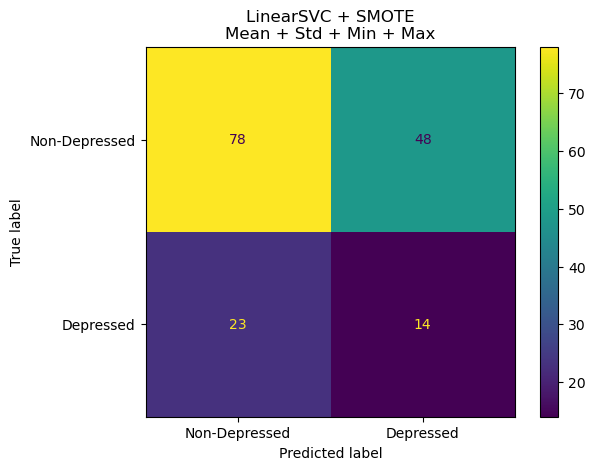

In [45]:
cm = confusion_matrix(
    y,
    oof_predictions
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Non-Depressed",
        "Depressed"
    ]
)

disp.plot()

plt.title(
    "LinearSVC + SMOTE\n"
    "Mean + Std + Min + Max"
)

plt.show()

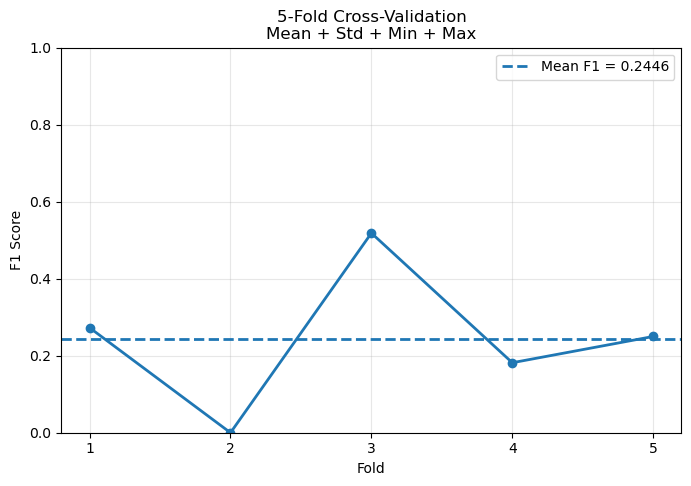

In [47]:
fold_numbers = np.arange(1, len(scores) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    fold_numbers,
    scores,
    marker="o",
    linewidth=2
)

plt.axhline(
    mean_f1,
    linestyle="--",
    linewidth=2,
    label=f"Mean F1 = {mean_f1:.4f}"
)

plt.xlabel("Fold")
plt.ylabel("F1 Score")

plt.title(
    "5-Fold Cross-Validation\n"
    "Mean + Std + Min + Max"
)

plt.xticks(fold_numbers)
plt.ylim(0, 1)

plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

In [55]:
final_results = {
    "Model": "LinearSVC + Balanced Class Weight",
    "Features": "Mean + Std + Min + Max",
    "Input Features": X.shape[1],
    "Selected Features": 10,
    "CV Folds": 5,
    "Mean F1": mean_f1,
    "Std F1": std_f1,
    "Accuracy": accuracy_score(y, oof_predictions),
    "Depressed Precision": precision_score(y, oof_predictions),
    "Depressed Recall": recall_score(y, oof_predictions),
    "Depressed F1": f1_score(y, oof_predictions)
}

results_df = pd.DataFrame([final_results])

display(results_df)

,Model,Features,Input Features,Selected Features,CV Folds,Mean F1,Std F1,Accuracy,Depressed Precision,Depressed Recall,Depressed F1
0,LinearSVC + Balanced Class Weight,Mean + Std + Min + Max,400,10,5,0.244613,0.167106,0.564417,0.225806,0.378378,0.282828
